In [1]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics.cluster import contingency_matrix 
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
#pd.set_option('display.max_rows', 200)
%matplotlib widget
SMALL_SIZE = 9
MEDIUM_SIZE = 9
BIGGER_SIZE = 14
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title
plt.rc('figure', autolayout=True)

In [3]:
import glob
path = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/cell_density/reports/"
result_files = glob.glob(path + "/results_summary_*.csv")
df = pd.read_csv(result_files[0])

In [4]:
for file in result_files[1:]:
    df = pd.concat([df, pd.read_csv(file)], ignore_index=True)
df

,ID,cell_types,output,use_perfect_registration,use_perfect_segmentation,teaching_imprecision,canvas_size,mic_spacing,ms_spacing,cell_density,...,m/z 0,STD m/z 0,m/z 1,STD m/z 1,m/z 2,STD m/z 2,m/z 3,STD m/z 3,FPR,ARI
0,f1396273-9da3-4d60-a691-f9d25d0a5915,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.05,...,0.036113,0.083117,0.014785,0.019321,0.015312,0.019283,0.033980,0.069822,0.0,1.000000
1,e8803b82-0e9c-46bc-9490-eeff4b83a0d5,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.05,...,0.013910,0.022118,0.011127,0.015306,0.014537,0.026790,0.063311,0.131762,0.0,0.583329
2,03c8082f-e45e-409e-8f26-bd9181a4547f,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.15,...,0.014025,0.021546,0.011731,0.016561,0.012750,0.020387,0.037063,0.094052,0.0,0.854749
3,4b474b10-2a76-4c0d-9d19-8aa0b0902a7a,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.20,...,0.013213,0.026491,0.014268,0.032811,0.016781,0.069136,0.036782,0.101629,0.0,0.850927
4,bfa09c66-2eae-4c29-b368-c09d022b65ab,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.25,...,0.012673,0.020047,0.011497,0.017967,0.014213,0.034704,0.064971,0.171680,0.0,0.901885
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,6e260fe2-a965-4f00-8b97-849f6ece9b88,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.35,...,0.010904,0.018762,0.010481,0.017510,0.011710,0.021619,0.049461,0.135743,0.0,0.805337
95,032a8951-fa90-4207-82c6-5bfe2d81d82c,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.40,...,0.010780,0.016956,0.010360,0.015260,0.023167,0.089115,0.049640,0.124925,0.0,0.479944
96,5a4dffdf-b74a-4110-8bcb-e42bddc5ea42,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.45,...,0.013705,0.026012,0.011324,0.016989,0.018479,0.042621,0.064036,0.139249,0.0,0.698771
97,94456b4c-f6c2-415b-9109-94eaeaed508b,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.50,...,0.012798,0.019872,0.013051,0.019317,0.021518,0.064753,0.066178,0.146016,0.0,0.686779


In [10]:
df['remove_ambiguous']

0     False
1     False
2     False
3     False
4     False
      ...  
94    False
95    False
96    False
97    False
98    False
Name: remove_ambiguous, Length: 99, dtype: bool

In [6]:
mean_diffusion = df.groupby('cell_density')[['cell_density', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].mean()
std_diffusion = df.groupby('cell_density')[['cell_density', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].std()

<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:3: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not w

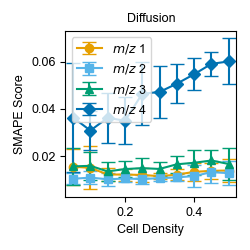

In [8]:
colors = ['#E69F00', '#56B4E9', '#009E73', '#0072B2']
markers = ['o', 's', '^', 'D']
labels = ['$\mathit{m/z}$ 1', '$\mathit{m/z}$ 2', '$\mathit{m/z}$ 3', '$\mathit{m/z}$ 4']
plt.figure(figsize=(2.5,2.5))
for i, mz in enumerate(['m/z 0', 'm/z 1', 'm/z 2', 'm/z 3']):
    plt.errorbar(mean_diffusion['cell_density'], mean_diffusion[mz], yerr=std_diffusion[mz], label=labels[i], color=colors[i], marker=markers[i], fmt='o-', capsize=5)
plt.xlabel('Cell Density')
plt.ylabel('SMAPE Score')
plt.title('Diffusion')
plt.tight_layout()
plt.legend()
plt.tight_layout()
plt.savefig(path + "evaluation/cell_density_results.png", dpi=600)
plt.show()

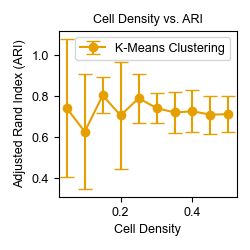

In [9]:
plt.figure(figsize=(2.5,2.5))
plt.errorbar(mean_diffusion['cell_density'], mean_diffusion['ARI'], yerr=std_diffusion['ARI'], label='K-Means Clustering', color=colors[0], fmt='o-', capsize=5)
plt.xlabel('Cell Density')
plt.ylabel('Adjusted Rand Index (ARI)')
plt.title('Cell Density vs. ARI')
plt.legend()
plt.tight_layout()
plt.savefig(path + "evaluation/cell_density_ARI_results.png", dpi=600)
plt.show()